## Análisis de Datos Meteorológicos con una API Pública
Obtener datos del clima de una ciudad usando la API de Open-Meteo (https://open-meteo.com/) y mostrar el pronóstico para Bilbao.

* Haz una petición a la API para que devuelva el pronóstico de las temperaturas para una semana en Bilbao. Tip: el parámetro correspondiente en el query es `temperature_2m` además de la latitud y la longitud.
* Procesa la respuesta en formato JSON para obtener dos listas: una con la lista de temperaturas y otra con las fechas-horas correspondientes.
* Crea un DataFrame con esas dos columnas: `Hora` y `Temperatura`
* Elige la gráfica adecuada y visualiza el pronóstico de temperaturas.

Para crear la variable `Hora` del DataFrame puedes introducir directamente la lista que se obtiene del campo `data["hourly"]["time"]` o procesar esa lista mediante el siguiente código:

`hours = pd.date_range(start=lista_de_horas, periods=len(temps), freq="H")`

In [ ]:
import requests


# Coordenadas de Kuna en Bilbao
latitude = 43.2540
longitude = -2.9230


url = f"https://api.open-meteo.com/v1/forecast?latitude={latitude}&longitude={longitude}&hourly=temperature_2m"  # Aquí vienen el resto de los parámetros

In [29]:
r = requests.get(url)

In [33]:
data = r.json()

In [42]:
lst_dt = data['hourly']['time']
lst_T = data['hourly']['temperature_2m']

In [43]:
import pandas as pd

In [49]:
lst_dt_ = pd.date_range(start=lst_dt[0], periods=len(lst_T), freq="H")

In [50]:
df = pd.DataFrame({'Horas': lst_dt_, 'Temperaturas [ºC]': lst_T})

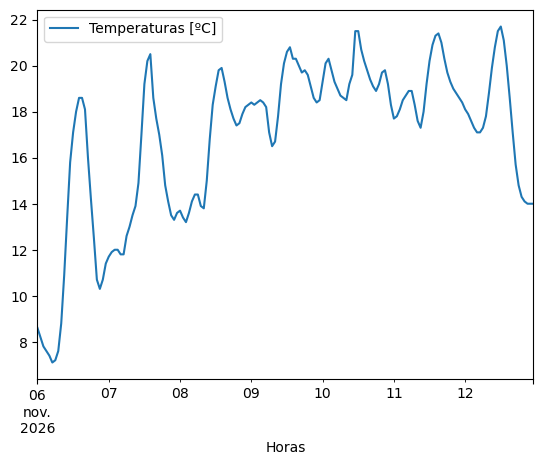

In [52]:
df.plot(x='Horas', y='Temperaturas [ºC]');